In [ ]:
import math
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
import numpy as np

df = pd.read_csv('StudentPerformanceFactors.csv')
df.dropna(inplace=True) # Ensure data is clean after loading
display(df.head())

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:
# Get the number of samples (rows) in the DataFrame
num_samples = df.shape[0]
print(f"The DataFrame contains {num_samples} samples.")

The DataFrame contains 6378 samples.


In [ ]:
#find and report total number of nulls and duplicate values
print(f"Null values: {df.isnull().sum().sum()}")
print(f"Duplicate values: {df.duplicated().sum()}")

Null values: 0
Duplicate values: 0


In [ ]:
#find number of nulls per column
total_nulls = df.isnull().sum()
display(total_nulls[total_nulls > 0].to_frame(name = 'Nulls').rename_axis('Columns'))

,Nulls
Columns,


In [ ]:
#drop null values
df.dropna(inplace = True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6378 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6378 non-null   int64 
 1   Attendance                  6378 non-null   int64 
 2   Parental_Involvement        6378 non-null   object
 3   Access_to_Resources         6378 non-null   object
 4   Extracurricular_Activities  6378 non-null   object
 5   Sleep_Hours                 6378 non-null   int64 
 6   Previous_Scores             6378 non-null   int64 
 7   Motivation_Level            6378 non-null   object
 8   Internet_Access             6378 non-null   object
 9   Tutoring_Sessions           6378 non-null   int64 
 10  Family_Income               6378 non-null   object
 11  Teacher_Quality             6378 non-null   object
 12  School_Type                 6378 non-null   object
 13  Peer_Influence              6378 non-null   object
 1

In [ ]:
#Statistical information
print("Numerical Statistic:")
display(df.describe().T)
print("Categorical Statistics:")
display(df.describe(include = 'object').T)

Numerical Statistic:


,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6378.0,19.977109,5.985460,1.0,16.0,20.0,24.0,44.0
Attendance,6378.0,80.020853,11.550723,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6378.0,7.034964,1.468033,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6378.0,75.066165,14.400389,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6378.0,1.495296,1.233984,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6378.0,2.972719,1.028926,0.0,2.0,3.0,4.0,6.0
Exam_Score,6378.0,67.252117,3.914217,55.0,65.0,67.0,69.0,101.0


Categorical Statistics:


,count,unique,top,freq
Parental_Involvement,6378,3,Medium,3251
Access_to_Resources,6378,3,Medium,3204
Extracurricular_Activities,6378,2,Yes,3807
Motivation_Level,6378,3,Medium,3237
Internet_Access,6378,2,Yes,5893
Family_Income,6378,3,Low,2582
Teacher_Quality,6378,3,Medium,3826
School_Type,6378,2,Public,4434
Peer_Influence,6378,3,Positive,2553
Learning_Disabilities,6378,2,No,5710


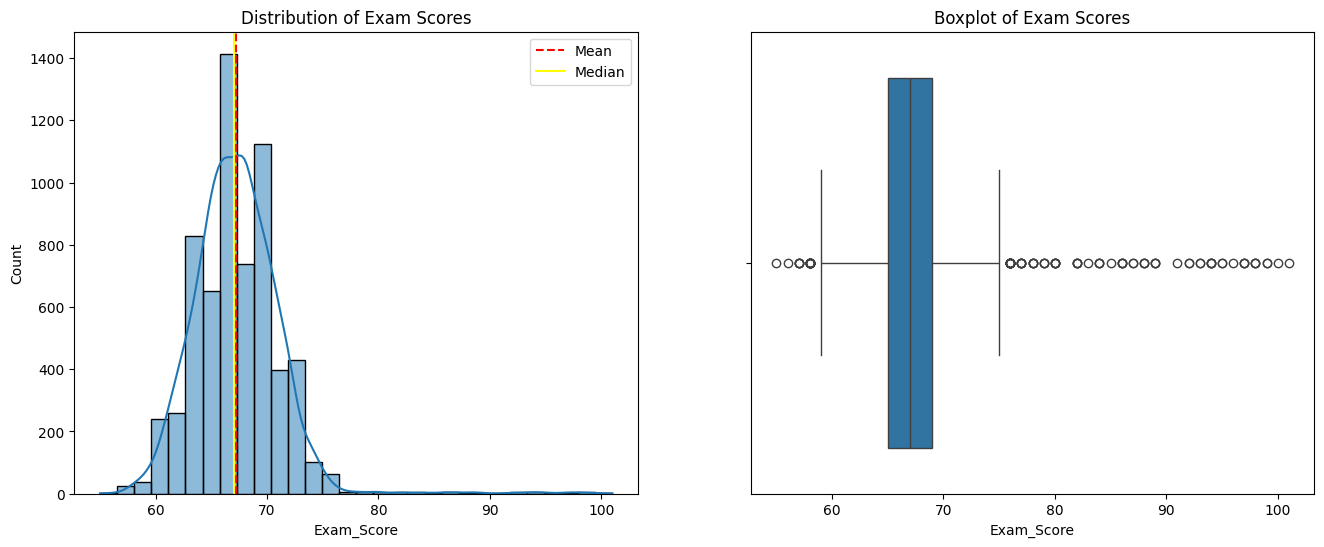

Exam Score Statistics:
Mean:     67.25
Median:   67.00
Skewness: 1.6658
Kurtosis: 10.6562


In [ ]:
# Data distribution of Exam_Score
fig_obj, ax_list = plt.subplots(1, 2, figsize=(16, 6))

# Histogram
sns.histplot(df['Exam_Score'], kde=True, bins=30, ax=ax_list[0])
ax_list[0].axvline(df['Exam_Score'].mean(), color='red', linestyle='--', label='Mean')
ax_list[0].axvline(df['Exam_Score'].median(), color='yellow', linestyle='-', label='Median')
ax_list[0].set_title('Distribution of Exam Scores')
ax_list[0].legend()

# Boxplot
sns.boxplot(x=df['Exam_Score'], ax=ax_list[1])
ax_list[1].set_title('Boxplot of Exam Scores')

plt.show()

# Statistical Summary
print("Exam Score Statistics:")
print(f"Mean:     {df['Exam_Score'].mean():.2f}")
print(f"Median:   {df['Exam_Score'].median():.2f}")
print(f"Skewness: {df['Exam_Score'].skew():.4f}")
print(f"Kurtosis: {df['Exam_Score'].kurt():.4f}")


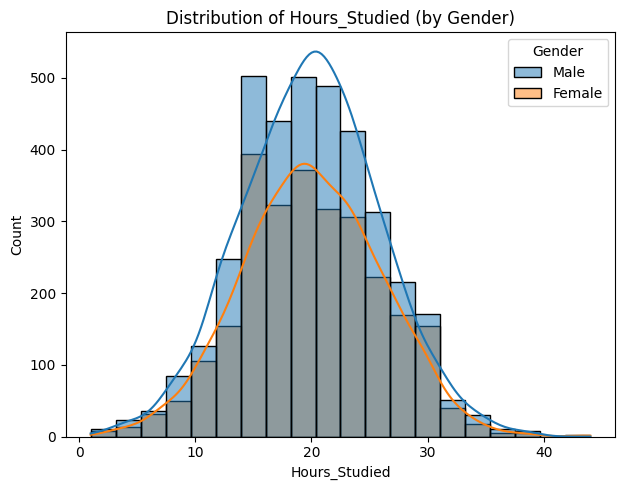

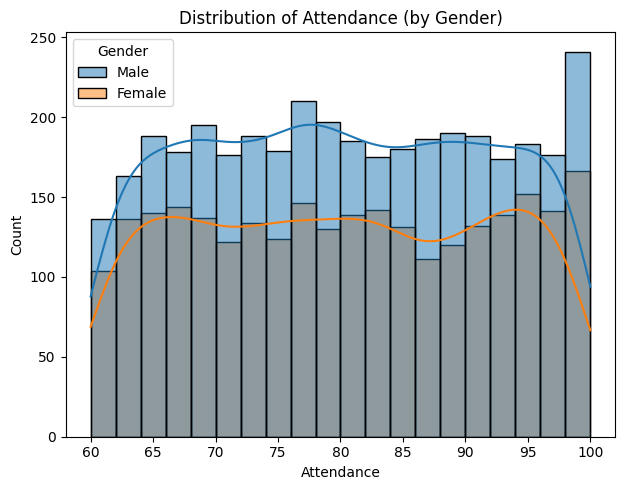

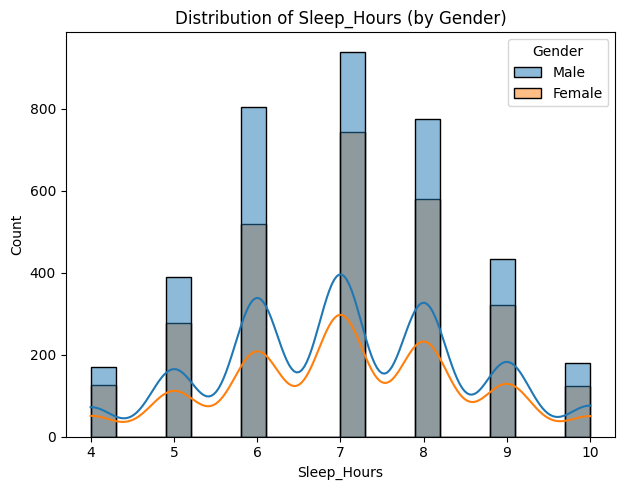

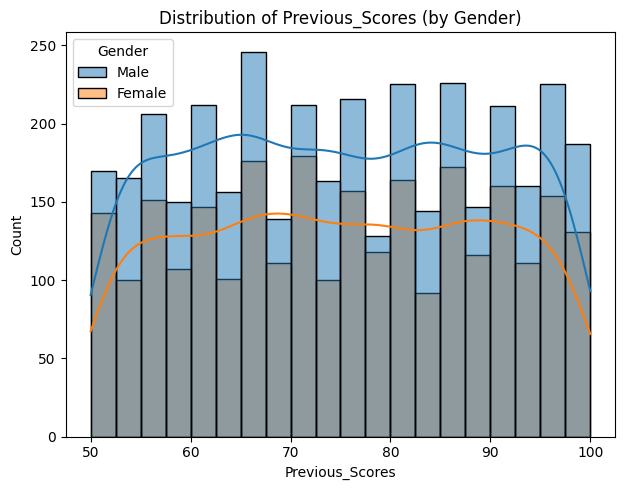

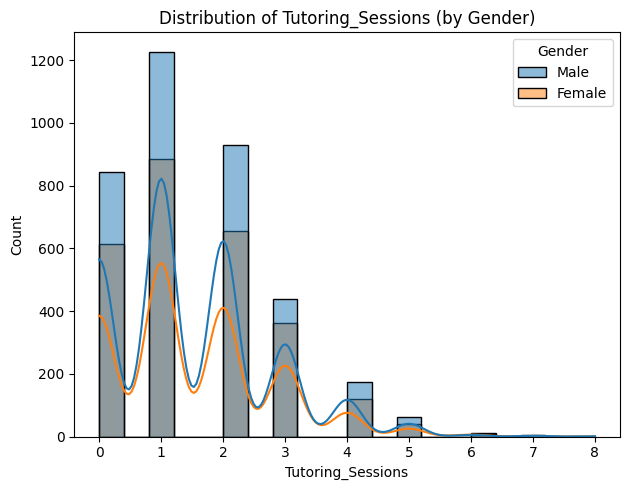

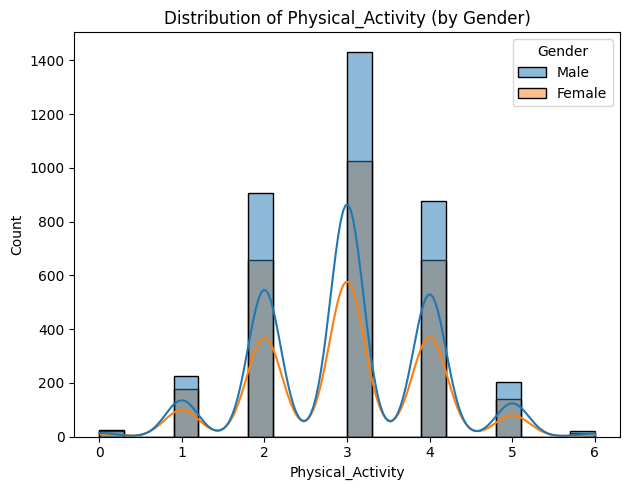

In [ ]:
# Data distribution of each feature by gender
numerical_cols = df.select_dtypes(include=['number']).columns.drop('Exam_Score')

for col in numerical_cols:
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    sns.histplot(data=df, x=col, hue='Gender', kde=True, bins=20, alpha=0.5)
    plt.title(f'Distribution of {col} (by Gender)')

    plt.tight_layout()
    plt.show()
    print()


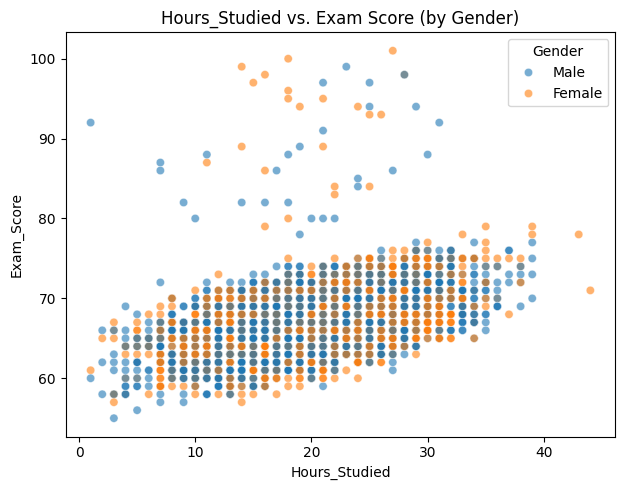

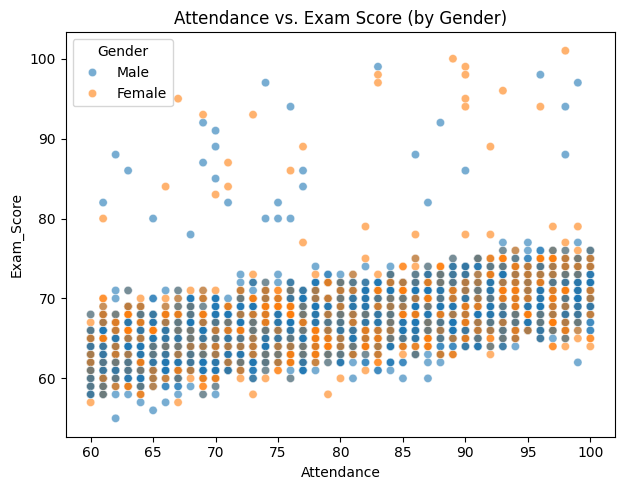

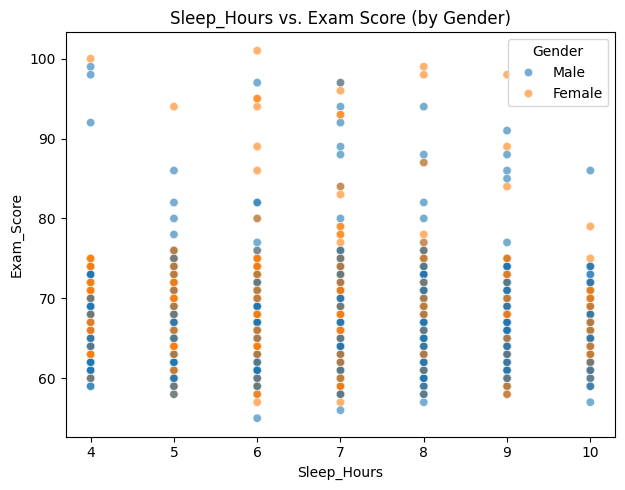

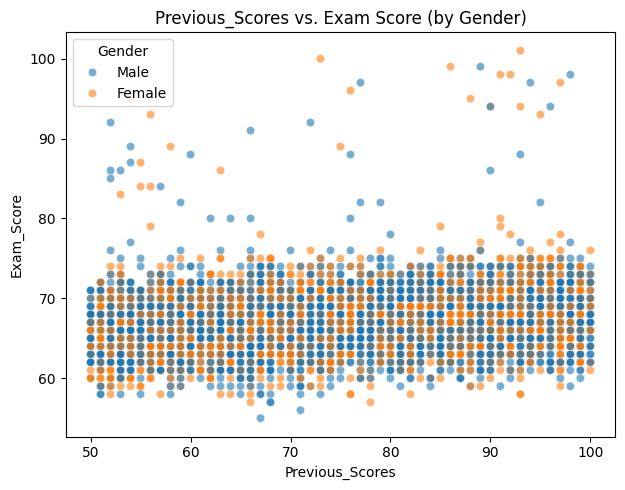

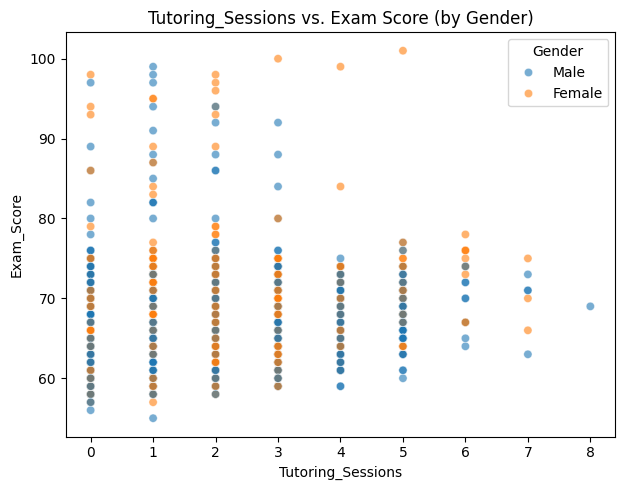

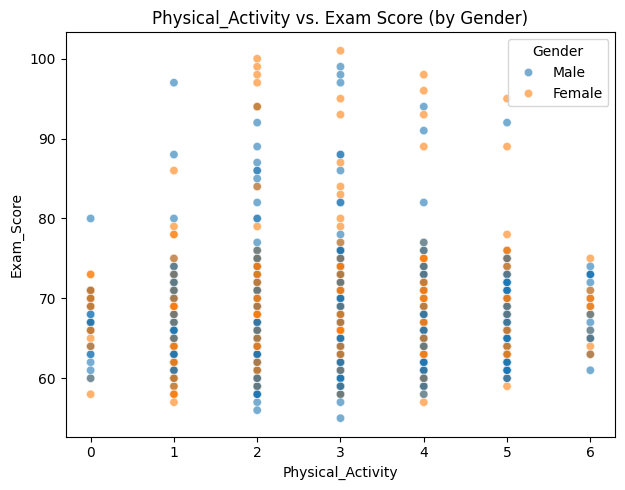

In [ ]:
# Feature relationship with target
numerical_cols = df.select_dtypes(include=['number']).columns.drop('Exam_Score')

for col in numerical_cols:
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 2)
    sns.scatterplot(data=df, x=col, y='Exam_Score', hue='Gender', alpha=0.6)
    plt.title(f'{col} vs. Exam Score (by Gender)')

    plt.tight_layout()
    plt.show()
    print()

In [ ]:
def plot_categorical_counts(df, columns, color_palette='Reds'):

    num_columns = 2
    num_rows = math.ceil(len(columns) / num_columns)

    plt.figure(figsize=(15, num_rows * 5))

    for index, column in enumerate(columns):
        plt.subplot(num_rows, num_columns, index + 1)
        sns.countplot(data=df, x=column, palette=color_palette)
        plt.title(f'Count of {column}', fontsize=12, fontweight='bold')
        plt.xticks(rotation=15)

    plt.tight_layout()
    plt.show()

In [ ]:
def plot_categorical_impact(df, feature_columns, target_column, color_palette='Reds'):

    num_plots_per_row = 2
    num_rows = math.ceil(len(feature_columns) / num_plots_per_row)

    plt.figure(figsize=(16, num_rows * 6))

    for idx, feature in enumerate(feature_columns):
        plt.subplot(num_rows, num_plots_per_row, idx + 1)
        sns.boxplot(data=df, x=feature, y=target_column, palette=color_palette)
        plt.title(f'Impact of {feature} on {target_column}', fontsize=12, fontweight='bold')
        plt.grid(axis='y', linestyle='--', alpha=0.5)
        plt.xticks(rotation=15)

    plt.tight_layout()
    plt.show()


/tmp/ipykernel_2019/3801276938.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette=color_palette)
/tmp/ipykernel_2019/3801276938.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette=color_palette)
/tmp/ipykernel_2019/3801276938.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=column, palette=color_palette)
/tmp/ipykernel_2019/3801276938.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` varia

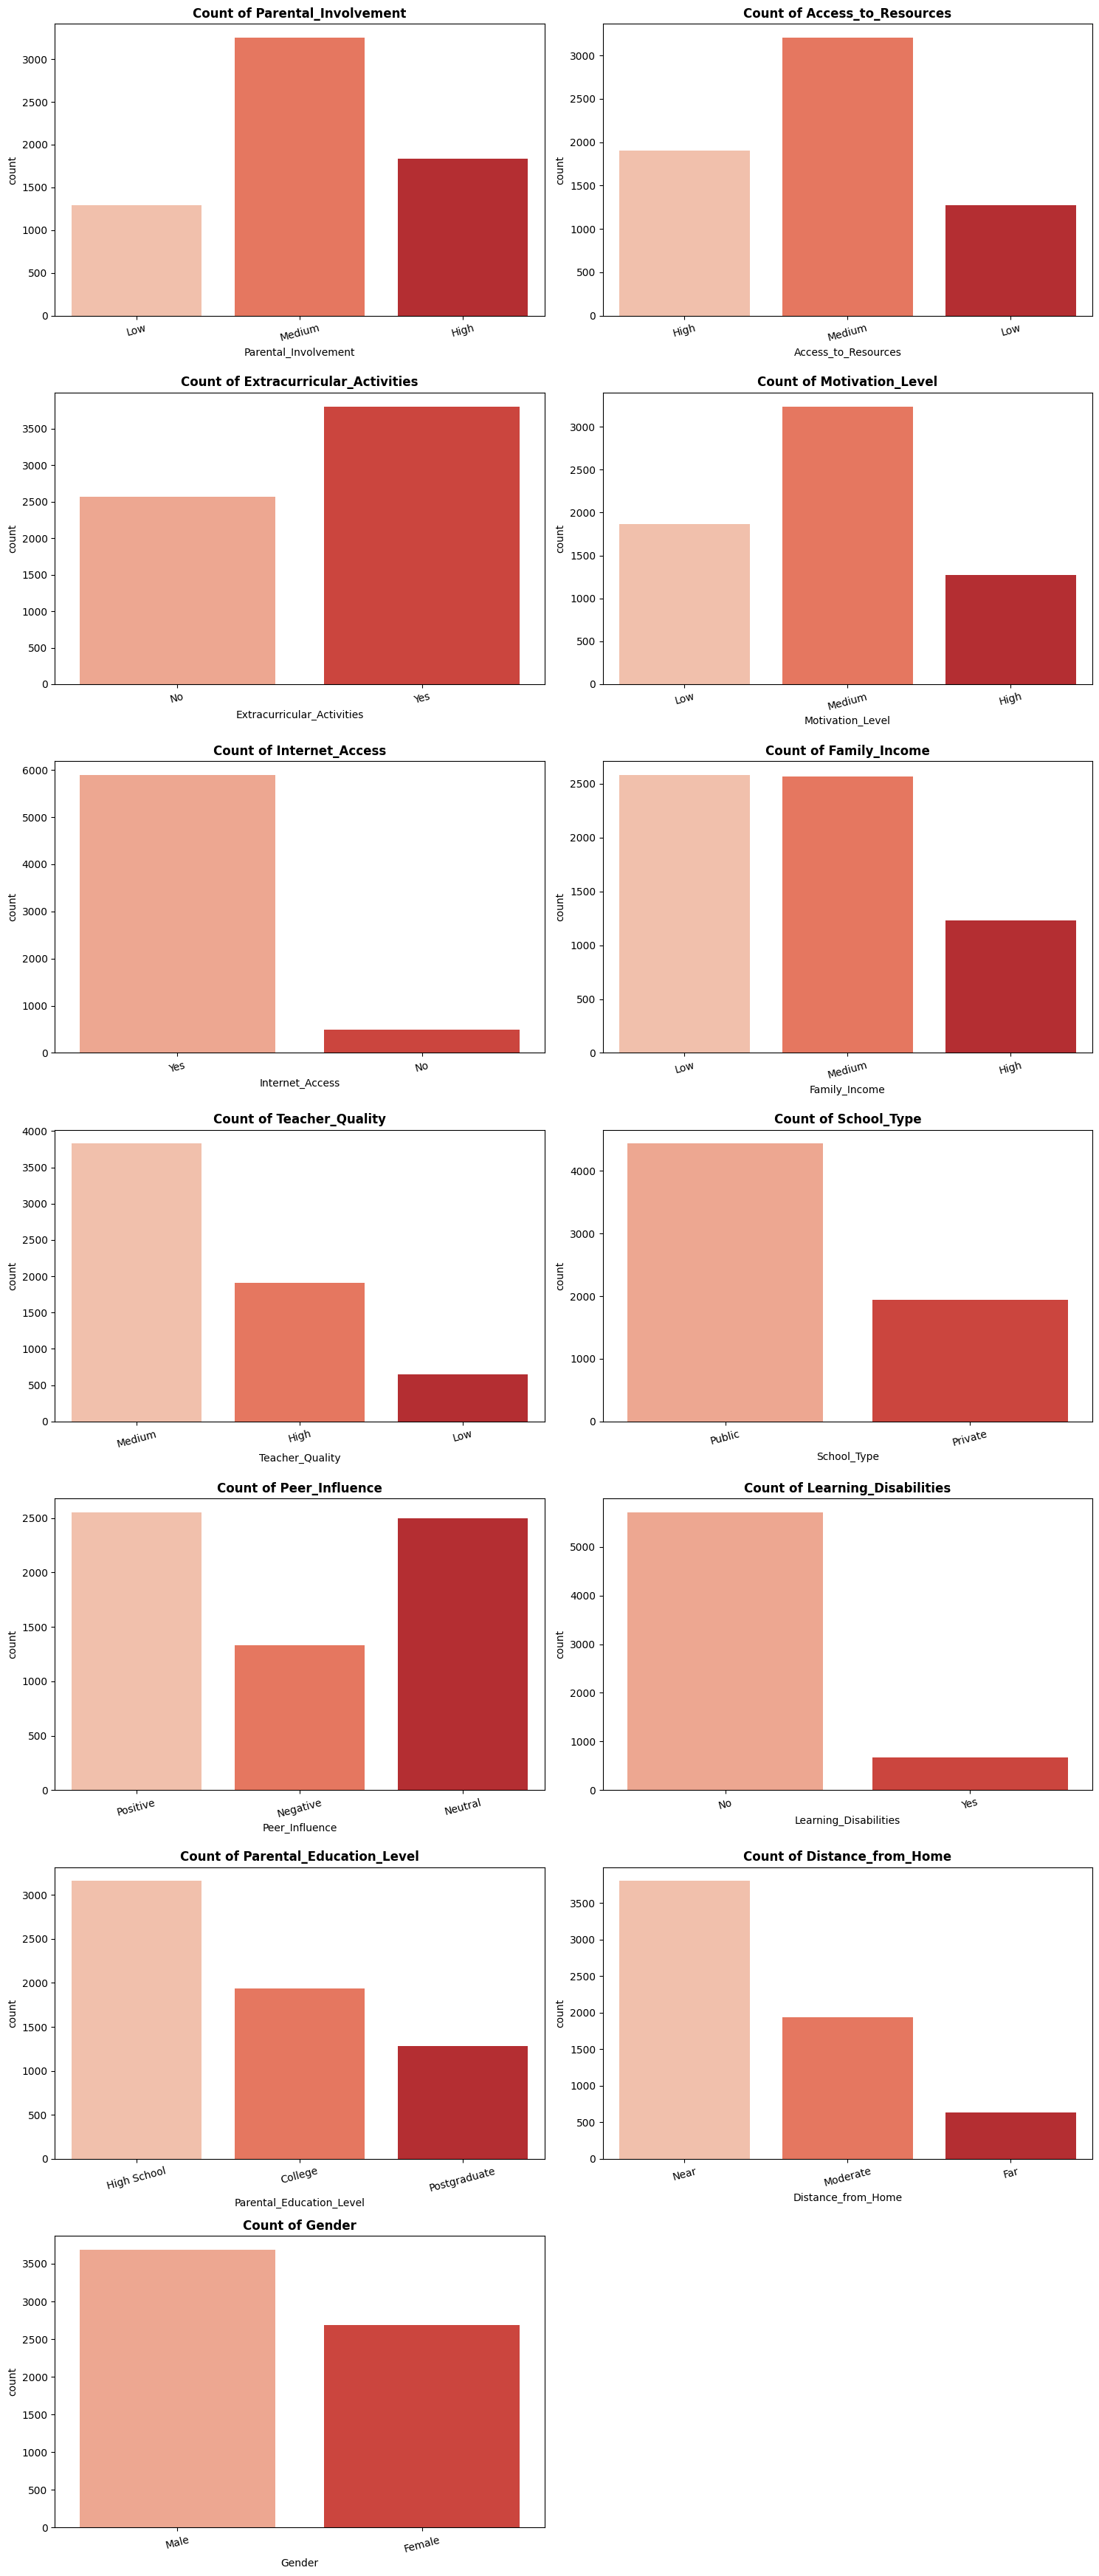

In [ ]:
categorical_cols = df.select_dtypes(include=['object']).columns

plot_categorical_counts(df, categorical_cols, color_palette='Reds')


/tmp/ipykernel_2019/883196545.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=feature, y=target_column, palette=color_palette)
/tmp/ipykernel_2019/883196545.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=feature, y=target_column, palette=color_palette)
/tmp/ipykernel_2019/883196545.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=feature, y=target_column, palette=color_palette)
/tmp/ipykernel_2019/883196545.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will

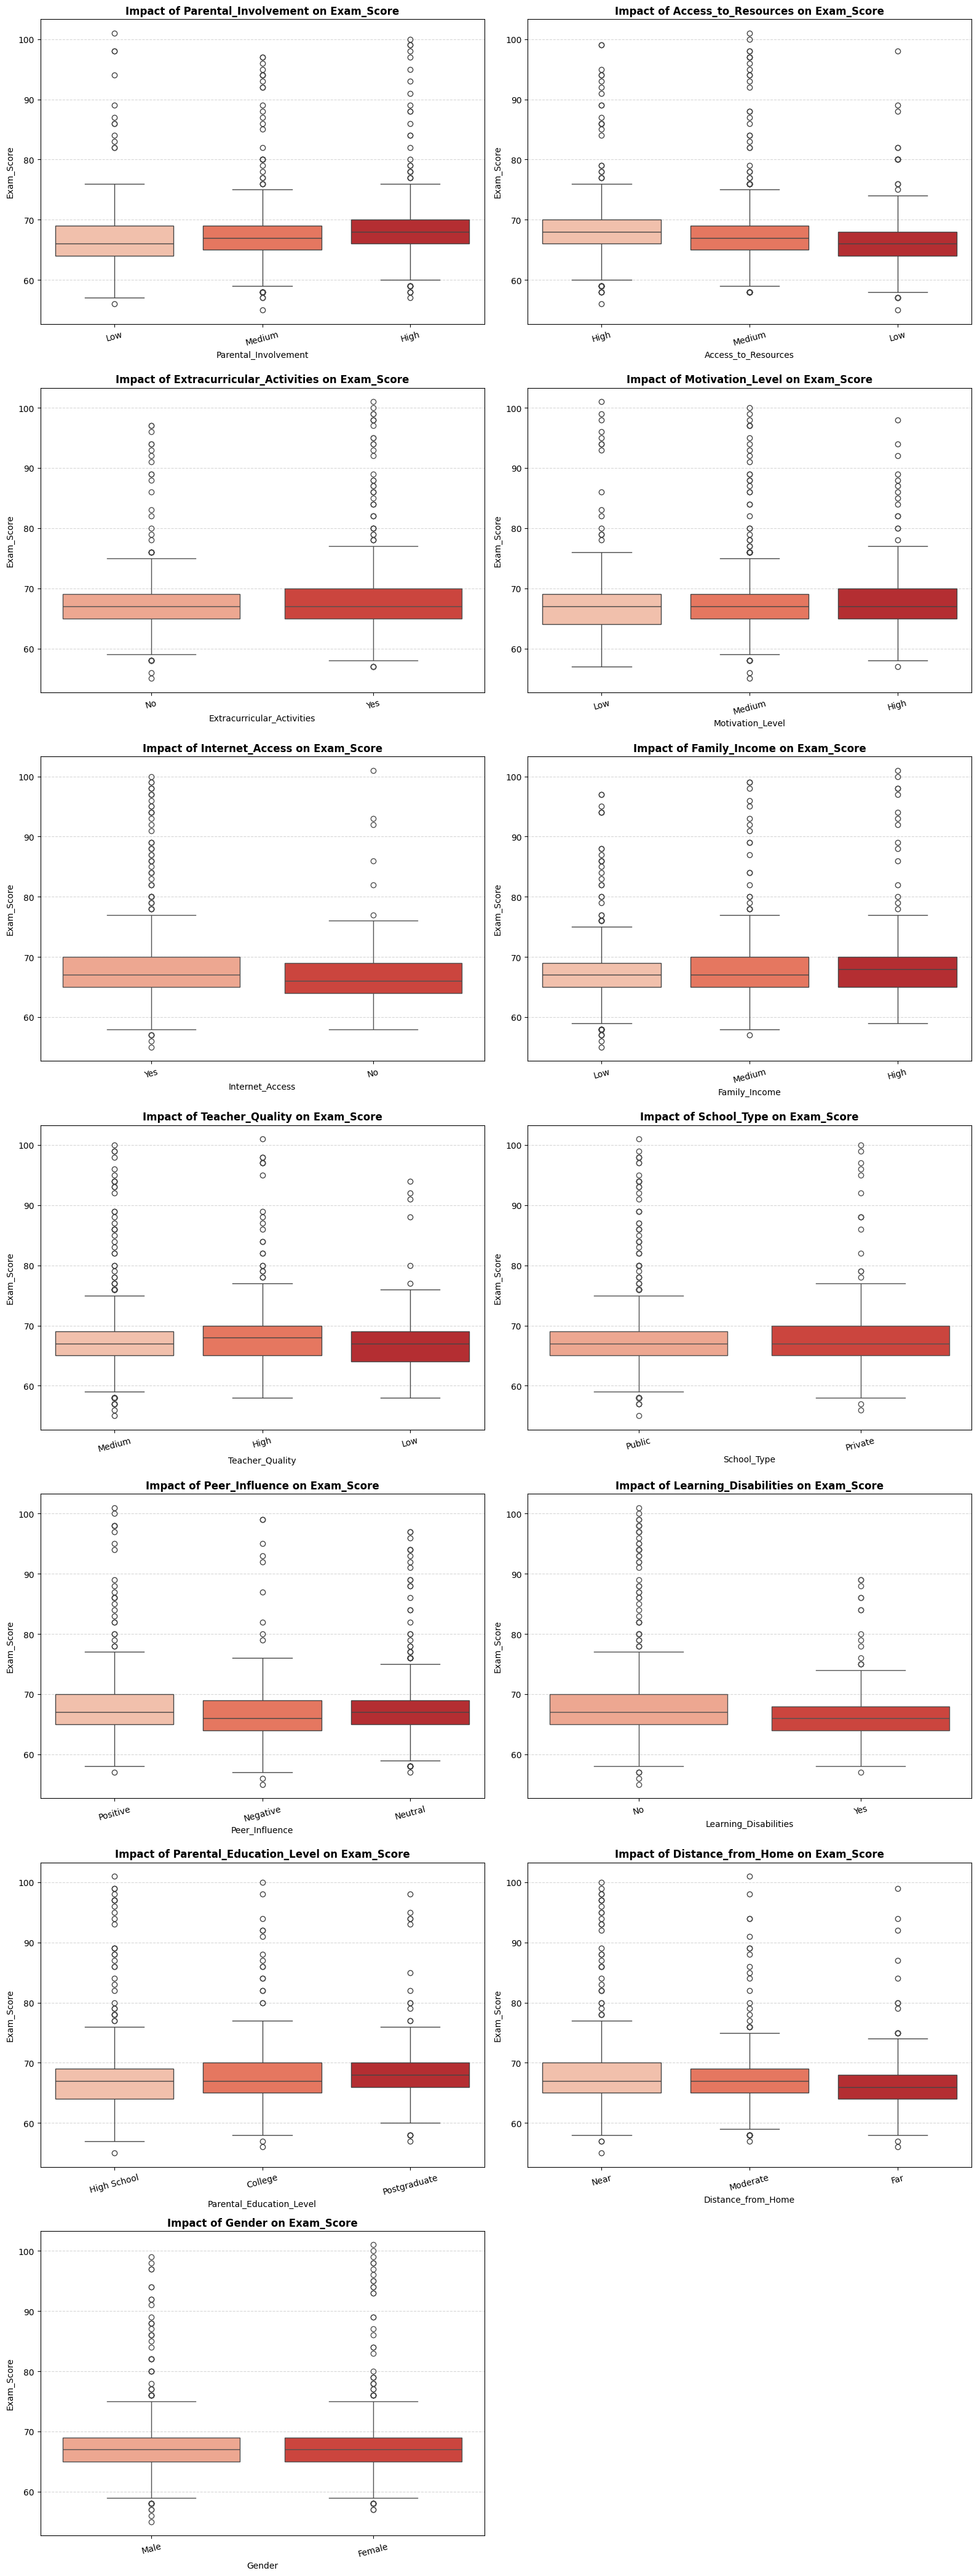

In [ ]:
plot_categorical_impact(df, categorical_cols, target_column='Exam_Score', color_palette='Reds')

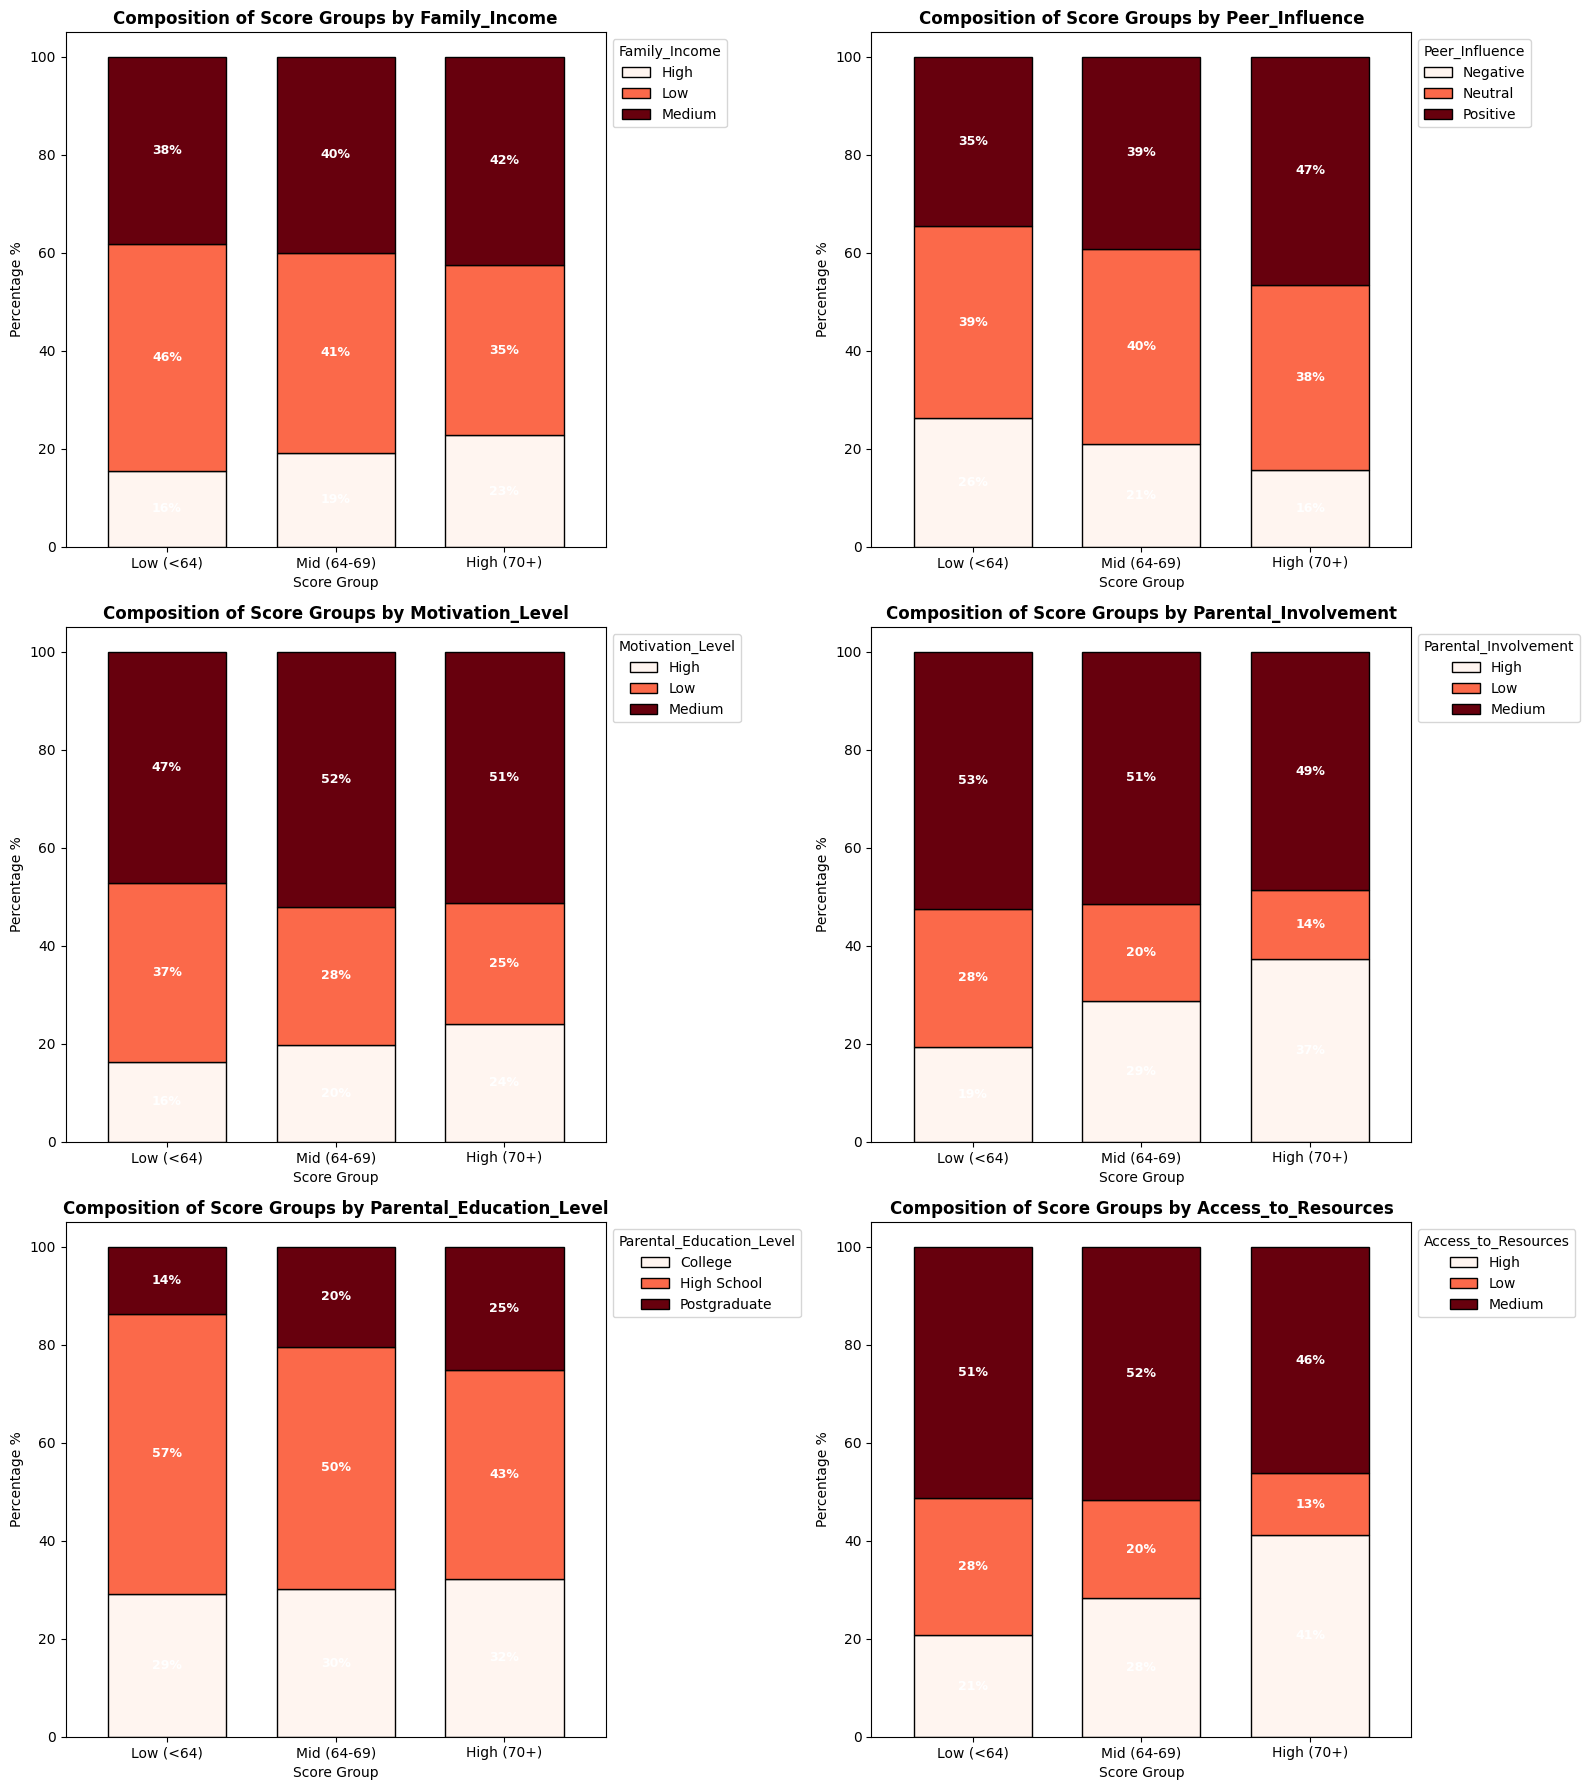

In [ ]:
df['Score_Segment'] = pd.cut(
    df['Exam_Score'],
    bins=[0, 64, 69, 100],
    labels=['Low (<64)', 'Mid (64-69)', 'High (70+)']
)

features_to_plot = [
    'Family_Income',
    'Peer_Influence',
    'Motivation_Level',
    'Parental_Involvement',
    'Parental_Education_Level',
    'Access_to_Resources'
]

num_cols = 2
num_rows = math.ceil(len(features_to_plot) / num_cols)

fig, axes = plt.subplots(num_rows, num_cols, figsize=(16, num_rows * 6))
axes = axes.flatten()

for idx, feature in enumerate(features_to_plot):
    crosstab_pct = (
        pd.crosstab(df['Score_Segment'], df[feature], normalize='index') * 100
    )

    crosstab_pct.plot(
        kind='bar',
        stacked=True,
        ax=axes[idx],
        colormap='Reds',
        edgecolor='black',
        width=0.7
    )

    axes[idx].set_title(
        f"Composition of Score Groups by {feature}",
        fontsize=12,
        fontweight='bold'
    )
    axes[idx].set_ylabel('Percentage %')
    axes[idx].set_xlabel('Score Group')
    axes[idx].tick_params(axis='x', rotation=0)
    axes[idx].legend(title=feature, bbox_to_anchor=(1.0, 1.0), loc='upper left')

    for container in axes[idx].containers:
        axes[idx].bar_label(
            container,
            fmt='%.0f%%',
            label_type='center',
            color='white',
            fontsize=9,
            weight='bold'
        )

# Remove extra subplot if number of axes > number of features
if len(features_to_plot) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


DataFrame head after all preprocessing (Family_Income mapped, categoricals encoded, numericals scaled):


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,0.511628,0.600,0.5,0.0,0.0,0.500000,0.46,0.5,1.0,0.000,0.0,1.0,1.0,1.0,0.500000,0.0,0.5,1.0,1.0,0.260870
1,0.418605,0.100,0.5,1.0,0.0,0.666667,0.18,0.5,1.0,0.250,0.5,1.0,1.0,0.0,0.666667,0.0,0.0,0.5,0.0,0.130435
2,0.534884,0.950,1.0,1.0,1.0,0.500000,0.82,1.0,1.0,0.250,0.5,1.0,1.0,0.5,0.666667,0.0,1.0,1.0,1.0,0.413043
3,0.651163,0.725,0.5,1.0,1.0,0.666667,0.96,1.0,1.0,0.125,0.5,1.0,1.0,0.0,0.666667,0.0,0.5,0.5,1.0,0.347826
4,0.418605,0.800,1.0,1.0,1.0,0.333333,0.30,1.0,1.0,0.375,0.5,0.0,1.0,0.5,0.666667,0.0,0.0,1.0,0.0,0.326087


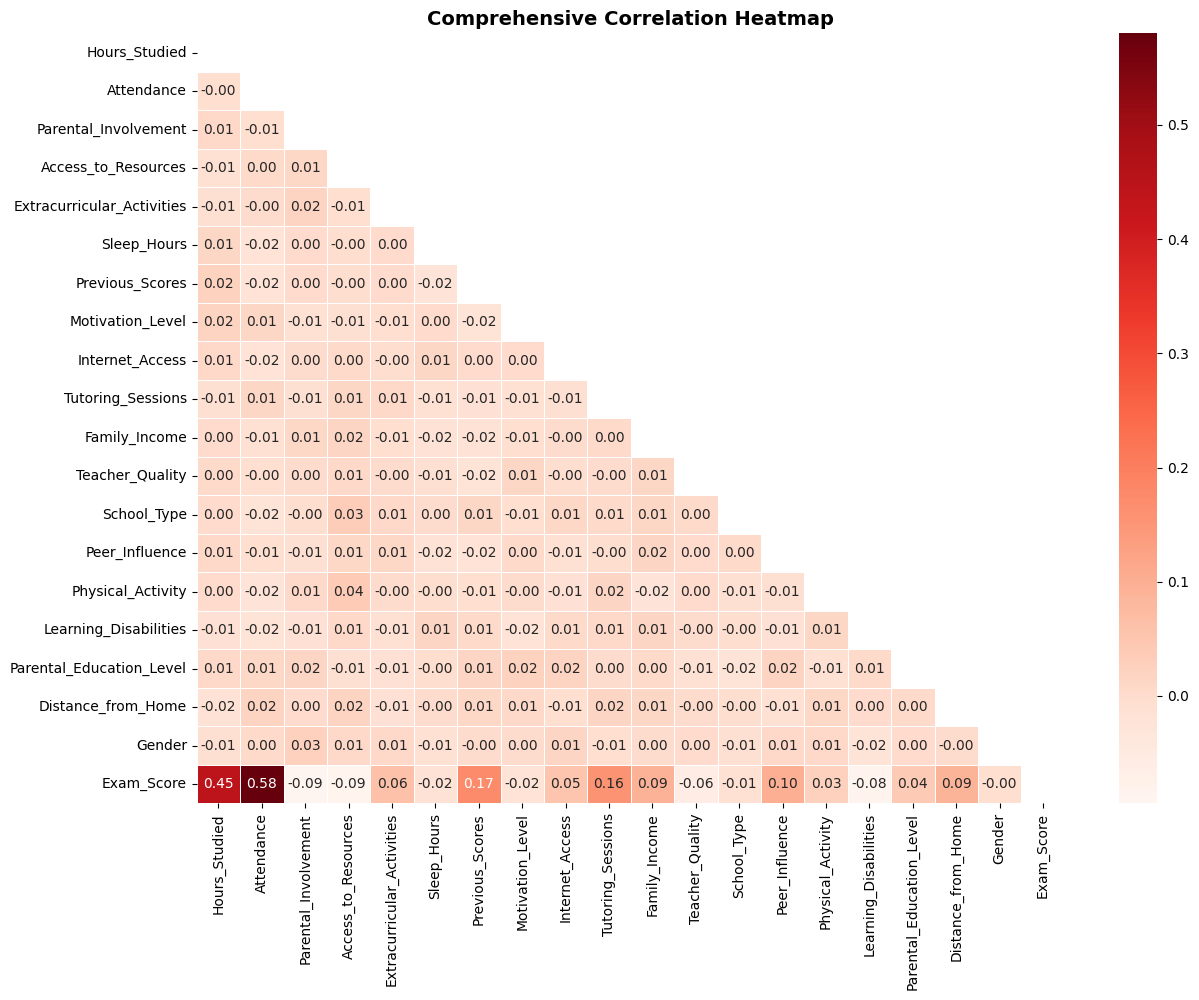

/tmp/ipykernel_2019/555795803.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


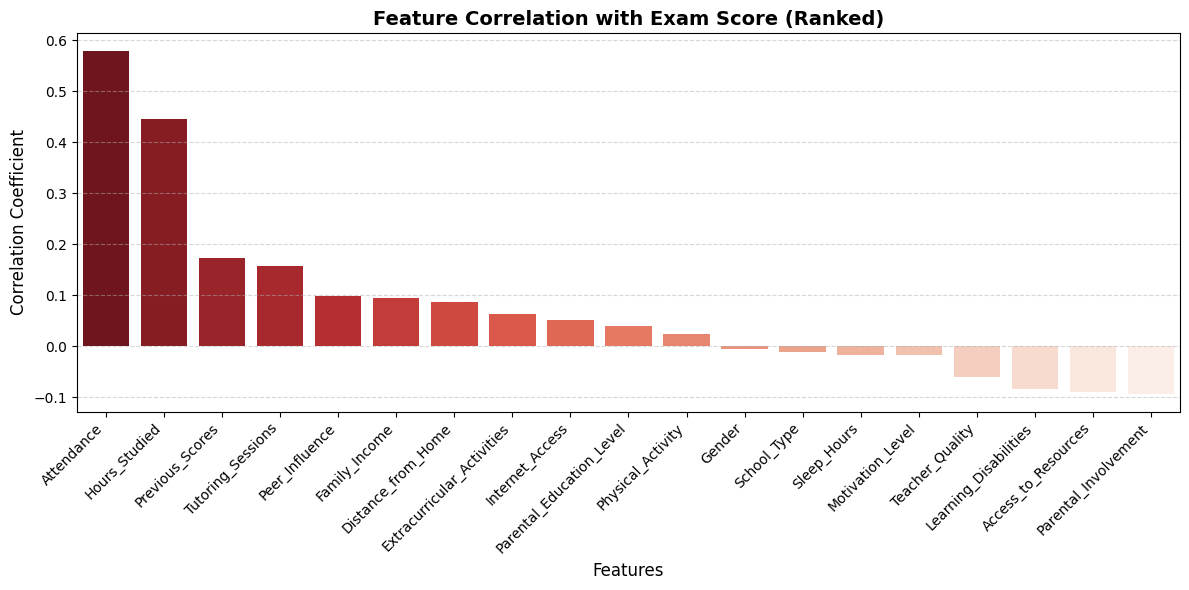

In [ ]:
income_mapping = {'Low': 1, 'Medium': 2, 'High': 3}
df['Family_Income'] = df['Family_Income'].map(income_mapping)

if 'Score_Segment' in df.columns:
    df.drop('Score_Segment', axis=1, inplace=True)

label_encoder = LabelEncoder()
categorical_columns = df.select_dtypes(include=['object', 'category']).columns

for column in categorical_columns:
    df[column] = label_encoder.fit_transform(df[column].astype(str))

numerical_features = df.select_dtypes(include=['int64', 'float64']).columns

scaler = MinMaxScaler()

df[numerical_features] = scaler.fit_transform(df[numerical_features])

print("DataFrame head after all preprocessing (Family_Income mapped, categoricals encoded, numericals scaled):")
display(df.head())

plt.figure(figsize=(14, 10))
correlation_matrix = df.corr()

upper_triangle_mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='Reds',
    mask=upper_triangle_mask,
    linewidths=0.5
)

plt.title('Comprehensive Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

exam_score_corr = (
    correlation_matrix['Exam_Score']
    .drop('Exam_Score')
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=exam_score_corr.index,
    y=exam_score_corr.values,
    palette='Reds_r'
)

plt.title('Feature Correlation with Exam Score (Ranked)', fontsize=14, fontweight='bold')
plt.ylabel('Correlation Coefficient', fontsize=12)
plt.xlabel('Features', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import joblib
import numpy as np

In [ ]:
# Define Features and Target
X = df.drop('Exam_Score', axis=1)
y = df['Exam_Score']

# 60/20/20 Split
# First split: Train (60%) + Temp (40%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, random_state=42
)

# Second split: Validation (20%) + Test (20%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)
print("Data Split Shapes:")
print(f"Train:      {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Test:       {X_test.shape}")

Data Split Shapes:
Train:      (3826, 19)
Validation: (1276, 19)
Test:       (1276, 19)


In [ ]:
# Scaling (Fit on Train)
std_cols = ['Hours_Studied', 'Sleep_Hours', 'Physical_Activity']
minmax_cols = ['Attendance', 'Previous_Scores']

scaler_std = StandardScaler()
scaler_mm = MinMaxScaler()

# Fit on train
X_train[std_cols] = scaler_std.fit_transform(X_train[std_cols])
X_val[std_cols]   = scaler_std.transform(X_val[std_cols])
X_test[std_cols]  = scaler_std.transform(X_test[std_cols])

X_train[minmax_cols] = scaler_mm.fit_transform(X_train[minmax_cols])
X_val[minmax_cols]   = scaler_mm.transform(X_val[minmax_cols])
X_test[minmax_cols]  = scaler_mm.transform(X_test[minmax_cols])

print("\nScaled Training Data Preview:")
display(X_train.head())


Scaled Training Data Preview:


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
4453,0.339246,0.150,1.0,0.5,1.0,2.020734,0.90,1.0,1.0,0.125,0.5,1.0,0.0,0.0,0.034959,0.0,0.5,1.0,1.0
3899,0.339246,0.000,0.5,0.5,0.0,-0.022789,0.66,1.0,0.0,0.375,0.5,1.0,1.0,1.0,-1.889572,0.0,0.0,1.0,0.0
2465,0.843372,0.550,0.0,1.0,0.0,1.339560,0.44,0.0,1.0,0.000,1.0,1.0,1.0,1.0,-2.851837,0.0,0.0,1.0,0.0
2463,-1.173132,0.800,1.0,0.0,1.0,-0.022789,0.40,0.5,1.0,0.500,0.0,1.0,1.0,0.5,0.034959,0.0,0.5,1.0,1.0
5071,-0.164880,0.175,1.0,0.5,0.0,2.020734,0.00,1.0,1.0,0.000,1.0,1.0,1.0,1.0,0.034959,0.0,0.5,1.0,1.0


In [ ]:
# Baseline Model: Linear Regression
lr_model = LinearRegression()

# Train on training set
lr_model.fit(X_train, y_train)

# Validate on validation set
val_pred = lr_model.predict(X_val)

r2_val = r2_score(y_val, val_pred)
rmse_val = np.sqrt(mean_squared_error(y_val, val_pred))

print("\nValidation Performance (Used for Model Selection):")
print(f" • R2 Score: {r2_val:.4f}")
print(f" • RMSE:     {rmse_val:.2f}")


Validation Performance (Used for Model Selection):
 • R2 Score: 0.6970
 • RMSE:     0.05


In [ ]:
# Final Evaluation on Test Set
test_pred = lr_model.predict(X_test)

r2_test = r2_score(y_test, test_pred)
rmse_test = np.sqrt(mean_squared_error(y_test, test_pred))

print("\nFINAL TEST PERFORMANCE (Untouched Data):")
print(f" • R2 Score: {r2_test:.4f}")
print(f" • RMSE:     {rmse_test:.2f}")


FINAL TEST PERFORMANCE (Untouched Data):
 • R2 Score: 0.6192
 • RMSE:     0.05


In [ ]:
# Save Model
joblib.dump(lr_model, "linear_regression_model.pkl")
joblib.dump(scaler_std, "std_scaler.pkl")
joblib.dump(scaler_mm, "minmax_scaler.pkl")

print("\nModel and scalers saved!")


Model and scalers saved!
